# floodfusion — a walkthrough on one small synthetic event

Everything below runs **offline on a CPU in about a minute**: a physics-based synthetic flood event,
its analysis-ready stack, a basin-blocked split, a (deliberately tiny) cross-attention fusion model,
calibration on validation, and the operational product with its exclusion mask. Every call is the
production code path; only the sizes are small.

The real-data results (Sen1Floods11 re-ingested, the EMSR664 Forlì case study) are in `reports/`.

In [1]:
import json
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import rasterio
import torch

from floodfusion import splits
from floodfusion.config import DataConfig, load_config
from floodfusion.data.chipping import read_event_stack
from floodfusion.data.encoding import ChipBand
from floodfusion.data.synthetic.benchmark import TINY_EVENTS, build_benchmark

torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 60, "savefig.dpi": 60})   # keep the committed notebook small
ROOT = Path.cwd() if (Path.cwd() / "configs").is_dir() else Path.cwd().parent
WORK = Path(tempfile.mkdtemp(prefix="floodfusion_walkthrough_"))
data_root = WORK / "data"
result = build_benchmark(data_root, specs=TINY_EVENTS, data_cfg=DataConfig(chip_size=64, train_stride=32, eval_stride=64))
print(len(result.records), "chips from", [e["event_id"] for e in result.events])

330 chips from ['T1_lowland', 'T2_hilly']


## 1. The analysis-ready stack

One grid, sixteen bands: post- and pre-event γ⁰ (VV, VH), their change, Sentinel-2 B3/B8/B11 and MNDWI,
slope, HAND, local incidence, the label, the validity bit field, the optical quality and land cover.
Flood water is dark in the post image and *darker than before*; terrain decides where radar sees nothing.

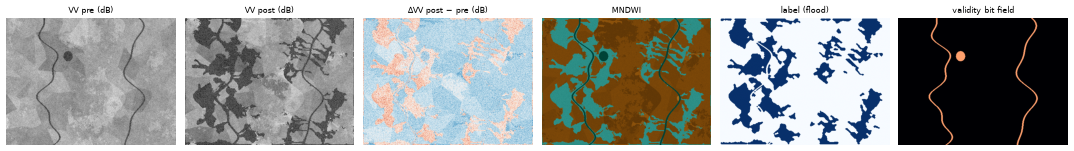

In [2]:
stack, grid, _ = read_event_stack(data_root / "events" / "T1_lowland" / "stack.tif")


def db(band):
    return np.where(stack[band] == -32768, np.nan, stack[band] / 100.0)


panels = [(db(ChipBand.VV_PRE), "VV pre (dB)", "gray"), (db(ChipBand.VV_POST), "VV post (dB)", "gray"),
          (db(ChipBand.DELTA_VV), "ΔVV post − pre (dB)", "RdBu"), (stack[ChipBand.MNDWI] / 1e4, "MNDWI", "BrBG"),
          (np.where(stack[ChipBand.LABEL] < 0, np.nan, stack[ChipBand.LABEL]), "label (flood)", "Blues"),
          (stack[ChipBand.VALIDITY], "validity bit field", "magma")]
fig, axes = plt.subplots(1, 6, figsize=(18, 3.6))
for ax, (img, title, cmap) in zip(axes, panels):
    ax.imshow(img, cmap=cmap)
    ax.set_title(title, fontsize=9)
    ax.axis("off")
plt.tight_layout()

## 2. A split that does not flatter

Chips are grouped by hydrological basin; no basin is in two splits, and chips near a boundary are buffered
out. A random chip split would put overlapping windows of the same river on both sides — the leakage row
of the ablation measures exactly how much that inflates a score.

In [3]:
overlay = WORK / "overlay.yaml"
overlay.write_text('''
data: {chip_root: chips, chip_size: 64, train_stride: 32, eval_stride: 64, num_workers: 0, basin_buffer_m: 200.0}
model: {encoder_channels: [16, 32, 64, 128], decoder_channels: [64, 32, 16, 8], attention_heads: 2,
        attention_head_dim: 16, norm_groups: 4}
train: {epochs: 3, warmup_epochs: 1, micro_batch_size: 2, grad_accum_steps: 2, early_stopping_patience: 0}
eval: {n_bootstrap: 300}
''')
config = ROOT / "configs" / "row09_fusion_crossattn.yaml"
splits.main(["--data-root", str(data_root), "--config", str(config), "--overlay", str(overlay),
             "--allow-short-buffer", "--pixels-per-event", "3000"])
frozen = json.loads((data_root / "chips" / "splits.json").read_text())
print({k: len(frozen[f"{k}_chips"]) for k in ("train", "val", "test")}, "| test basins:", frozen["test_basins"])

INFO floodfusion.splits: variogram range (median over events): VV 900 m, label 600 m; buffer 200 m


WARNING floodfusion.splits: basin_buffer_m=200 m does not exceed the measured autocorrelation range 900 m (docs/05 section 6.2): raise data.basin_buffer_m


WARNING floodfusion.splits: assign_basins: dropped 76 of 330 chips (23 %): {'footprint_crosses_boundary': 59, 'within_buffer_of_other_split': 17} — more than 20 %: basins too small for the chip size, or an implausibly large buffer; investigate


INFO floodfusion.splits: LOBO: 126/18/18 chips, basins ['T1_lowland_B0', 'T2_hilly_B1']/['T2_hilly_B0']/['T1_lowland_B1']; row-13 leak: 68 % of test pixels inside training windows


INFO floodfusion.splits: train-only SAR stats: mean [-15.65 -22.39 -11.3  -18.14  -4.35] std [7.26 7.82 3.26 3.84 6.87]


{'train': 126, 'val': 18, 'test': 18} | test basins: ['T1_lowland_B1']


## 3. Train, calibrate, score

The model: two encoders, cross-attention with queries from optical and keys/values from SAR, a per-pixel
quality gate, and a gated residual on the SAR stream (with the gate closed, the output is the SAR-only
path, bit for bit). Calibration — prior correction and temperature (Platt if clearly better) — is fitted
on validation, the threshold τ* = 1/(1+r) follows from a stated cost ratio, and a conformal threshold
bounds the expected per-chip miss rate.

In [4]:
from floodfusion.evaluate import evaluate_run
from floodfusion.train import fit, load_training_data

cfg = load_config(config, overlays=[overlay])
run_dir = WORK / "runs" / cfg.name / "seed42"
fit(load_training_data(cfg, data_root), run_dir, device=torch.device("cpu"), provenance={"data_root": str(data_root)})
ev = evaluate_run(run_dir, data_root=data_root, device=torch.device("cpu"), figures=False)
print(f"test macro IoU at tau*={ev['tau_star']:.2f}: {ev['macro_iou']:.3f} (raw scores: {ev['macro_iou_raw_tau_star']:.3f})")
print("calibration:", {k: round(v, 3) if isinstance(v, float) else v for k, v in ev["calibration"].items()
                       if k in ("method", "temperature", "offset")})
print("conformal:", {k: ev["conformal"][k] for k in ("alpha", "tau", "n", "test_mean_chip_fnr")})

INFO floodfusion.train: row09_fusion_crossattn seed 42 epoch 0: loss 2.0192 (focal 1.0578, dice 0.9615) gate 0.119/0.119 | val macro IoU 0.164 @0.020 AP 0.164 | lr 1.00e-04 | 0.00 GiB | 3.8 s


INFO floodfusion.train: row09_fusion_crossattn seed 42 epoch 1: loss 2.0086 (focal 1.0484, dice 0.9603) gate 0.118/0.118 | val macro IoU 0.181 @0.020 AP 0.209 | lr 5.05e-05 | 0.00 GiB | 4.1 s


INFO floodfusion.train: row09_fusion_crossattn seed 42 epoch 2: loss 2.0177 (focal 1.0586, dice 0.9592) gate 0.118/0.118 | val macro IoU 0.198 @0.025 AP 0.342 | lr 1.00e-06 | 0.00 GiB | 5.4 s


INFO floodfusion.evaluate: row09_fusion_crossattn [test]: macro IoU 0.636 [0.636, 0.636] at tau*=0.25 (raw-score 0.000, oracle 0.716), AP 0.913, T=0.12, ECE 0.2215 -> 0.1860


test macro IoU at tau*=0.25: 0.636 (raw scores: 0.000)
calibration: {'method': 'platt', 'temperature': 0.121, 'offset': 3.635}
conformal: {'alpha': 0.1, 'tau': 0.10073235770753436, 'n': 12, 'test_mean_chip_fnr': 0.0}


## 4. The product

Seven Cloud-Optimized GeoTIFFs with the structure of the Copernicus Global Flood Monitoring product, and a
STAC Item that links every input scene. Excluded pixels (shadow, layover, dense forest or urban) keep
their likelihood: the mask says *do not trust this*, it does not erase the evidence.

INFO floodfusion.products: package /tmp/floodfusion_walkthrough__kgnkie_/package: 3.98 km2 flood, 14.5 % excluded


INFO floodfusion.predict: wrote /tmp/floodfusion_walkthrough__kgnkie_/product.tif: 39823 flood pixels (3.98 km^2) at tau*=0.25


['https://stac-extensions.github.io/projection/v2.0.0/schema.json', 'https://stac-extensions.github.io/raster/v1.1.0/schema.json', 'https://stac-extensions.github.io/sat/v1.0.0/schema.json', 'https://stac-extensions.github.io/sar/v1.0.0/schema.json', 'https://stac-extensions.github.io/processing/v1.2.0/schema.json']
['advisory_flags', 'exclusion_mask', 'flags', 'likelihood', 'observed_flood', 'observed_water', 'reference_water']


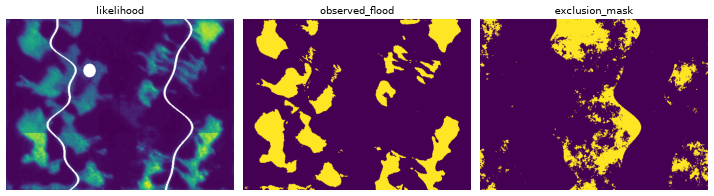

In [5]:
from floodfusion import predict

stack_path = data_root / "events" / "T1_lowland" / "stack.tif"
predict.main(["--run-dir", str(run_dir), "--stack", str(stack_path), "--out", str(WORK / "product.tif"),
              "--package", str(WORK / "package"), "--device", "cpu"])
layers = {n: rasterio.open(WORK / "package" / f"{n}.tif").read(1) for n in ("likelihood", "observed_flood", "exclusion_mask")}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (name, img) in zip(axes, layers.items()):
    ax.imshow(np.where(img == 255, np.nan, img), cmap="viridis")
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
item = json.loads((WORK / "package" / "item.json").read_text())
print(item["stac_extensions"])
print(sorted(item["assets"]))